# 04 · Embedding space: high- vs low-volatility days

High/low volatility = top/bottom quintile of |JISDOR log return| over all 1,168 modelled days. Headlines are those aligned to that day (published before the fixing).

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebook' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
FIG = 'report/figures/'
from src.analysis import embedding_space as es

## UMAP of e5 headline embeddings

/Users/harfi/Documents/Project/ugm/nlp3/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/harfi/Documents/Project/ugm/nlp3/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


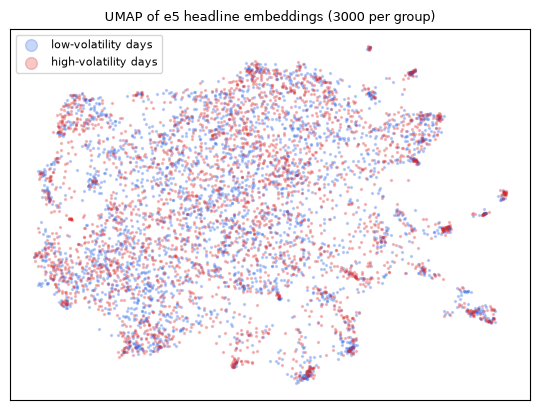

In [2]:
fig, arts, Z = es.umap_plot('e5', 3000, FIG + 'umap_volatility.png')

## Which topics are over-represented on high-volatility days?

trading_date,high,low,log2_lift,keywords
row_0,,,,
26,0.007,0.014,-0.950,"covid19, omicron, kasus, vaksin"
23,0.015,0.022,-0.570,"rusia, ukraina, perang, perang rusia"
4,0.043,0.052,-0.248,"indonesia, listrik, proyek, investasi"
9,0.034,0.040,-0.233,"kpk, kasus, korupsi, tersangka"
7,0.032,0.038,-0.224,"2023, kuartal, 2022, laba"
19,0.023,0.027,-0.209,"2023, 2022, lebaran, mudik"
0,0.051,0.057,-0.154,"saham, ipo, emiten, goto"
12,0.025,0.027,-0.142,"jokowi, presiden, ikn, presiden jokowi"
10,0.038,0.042,-0.121,"ihsg, saham, rekomendasi, rekomendasi saham"


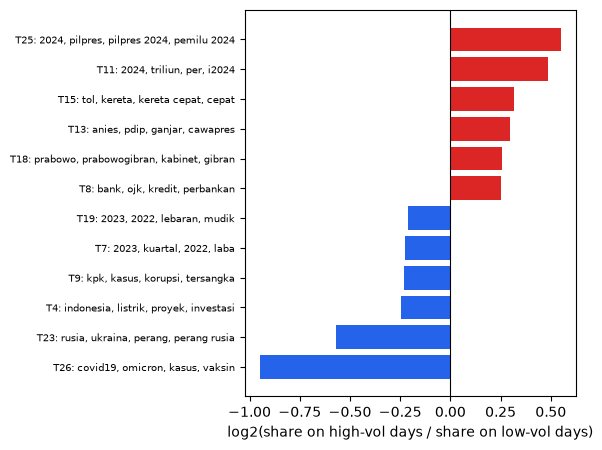

In [3]:
lift, fig = es.topic_lift(FIG + 'topic_lift.pdf')
lift.sort_values('log2_lift').round(3)

## Can daily embeddings separate high- from low-volatility days?

5-fold stratified LogReg on PCA-16 of the daily mean vector, per encoder (a descriptive check, not a forecast).

In [4]:
es.separability().round(3)

,table,days,auc_mean,auc_sd
0,word2vec_mean,415,0.615,0.061
1,fasttext_mean,415,0.614,0.058
2,indobert_mean,415,0.596,0.070
3,indobert_dapt_mean,415,0.619,0.080
4,e5_mean,415,0.631,0.065
